# Redes neurais

Neste notebook usamos as redes neurais da `rbg` (`MLPClassifier` e `MLPRegressor`) nos dois problemas do projeto: a classificação dos feijões (Dry Bean) e a regressão do aluguel (Rent99). Os dados e a divisão em treino e teste são os mesmos dos outros notebooks, para que os resultados possam ser comparados.

In [1]:
import time

import altair as alt
import numpy as np
import pandas as pd

from rbg.NeuralNetwork import MLPClassifier, MLPRegressor
from rbg.Preprocessing import Standard
from rbg.Utilities import Precision, Recall, F1Score, Accuracy, RMSE, train_test_split

from utils.dados import (SEED, ALVO_BEAN, FEATURES_BEAN, carregar_dry_bean, split_dry_bean,
                         carregar_rent99, split_rent99, salvar_resultados)
from utils.avaliacao import metricas_classificacao, metricas_regressao
from utils.graficos import configurar_altair, stylize

configurar_altair()

## Parte 1: classificação (Dry Bean)

In [2]:
df = carregar_dry_bean()

TARGET = ALVO_BEAN
FEATURES = FEATURES_BEAN

### Reconhecimento inicial

In [3]:
print(f'O Data frame escolhido contém uma série de dados sobre um conjunto extenso de feijões, cada coluna do data frame representa a medida de uma característica, sendo a última coluna representando a classe de cada feijão')
print(f'\n  Distribuídas entre {len(df[TARGET].unique())} classes, para cada uma das {df.shape[0]} amostras foram realizadas medições para {df.shape[1] - 1} características')

O Data frame escolhido contém uma série de dados sobre um conjunto extenso de feijões, cada coluna do data frame representa a medida de uma característica, sendo a última coluna representando a classe de cada feijão

  Distribuídas entre 7 classes, para cada uma das 13543 amostras foram realizadas medições para 16 características


### Usando a biblioteca para particionar os dados:

Usamos a mesma divisão estratificada dos outros modelos de classificação (sem as linhas duplicadas, 20% de cada classe no teste).

In [4]:
x_train, x_test, y_train, y_test = split_dry_bean(df)

print(x_train.shape, x_test.shape)

(10831, 16) (2712, 16)


## Pré-processamento

In [5]:
st = Standard()
st.fit(x_train)
x_train_norm = st.transform(x_train)
x_test_norm = st.transform(x_test)

### Escolhendo a arquitetura

Antes de construir a rede final, separamos 20% do treino como validação e comparamos algumas arquiteturas. A (64, 32) é a que usamos desde o início; as outras são uma menor e uma maior. O padronizador aqui é ajustado só na parte de treino, e o teste não entra nessa escolha.

In [6]:
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=SEED)

st_val = Standard()
st_val.fit(x_tr)
x_tr_norm = st_val.transform(x_tr)
x_val_norm = st_val.transform(x_val)

arquiteturas = [(32,), (64, 32), (128, 64), (64, 32, 16)]

comparacao = []
for camadas in arquiteturas:
    inicio = time.time()
    rede = MLPClassifier(
        hidden_layers=camadas,
        activation='relu',
        optimizer="adam",
        learning_rate=0.001,
        epochs=100,
        batch_size=150,
        random_state=SEED,
    )
    rede.fit(x_tr_norm, y_tr)
    comparacao.append({
        "hidden_layers": str(camadas),
        "acuracia_treino": float(Accuracy(rede.predict(x_tr_norm), y_tr)),
        "acuracia_validacao": float(Accuracy(rede.predict(x_val_norm), y_val)),
        "f1_macro_validacao": float(F1Score(rede.predict(x_val_norm), y_val).mean()),
        "tempo_s": round(time.time() - inicio, 1),
    })

comparacao = pd.DataFrame(comparacao)
comparacao.round(4)

,hidden_layers,acuracia_treino,acuracia_validacao,f1_macro_validacao,tempo_s
0,"(32,)",0.9339,0.9289,0.9419,0.8
1,"(64, 32)",0.9437,0.9229,0.9378,1.7
2,"(128, 64)",0.9514,0.9308,0.9420,3.3
3,"(64, 32, 16)",0.9460,0.9234,0.9368,2.0


In [7]:
melhor = comparacao.sort_values("acuracia_validacao", ascending=False).iloc[0]
camadas_escolhidas = eval(melhor["hidden_layers"])
print("Arquitetura escolhida pela validação:", camadas_escolhidas)

Arquitetura escolhida pela validação: (128, 64)


As quatro redes ficaram muito próximas na validação (entre 92,3% e 93,1% de acurácia), uma diferença pequena para as 2166 amostras de validação. A (128, 64) teve o melhor resultado (93,1%), um pouco acima da (64, 32) que usávamos (92,3%), então seguimos com ela. A rede de uma camada só com 32 neurônios chegou a 92,9%, ou seja, aumentar a rede ajuda pouco nesse problema.

### Construindo a rede:

In [8]:
Rede = MLPClassifier(
    hidden_layers=camadas_escolhidas,
    activation='relu',
    optimizer="adam",
    learning_rate=0.001,
    epochs=100,
    batch_size=150,
    random_state=SEED,
)

In [9]:
Rede.fit(x_train_norm, y_train)

y_previsto = Rede.predict(x_test_norm)

A rede guarda a perda média de cada época em `history`, então dá para ver se o treino convergiu.

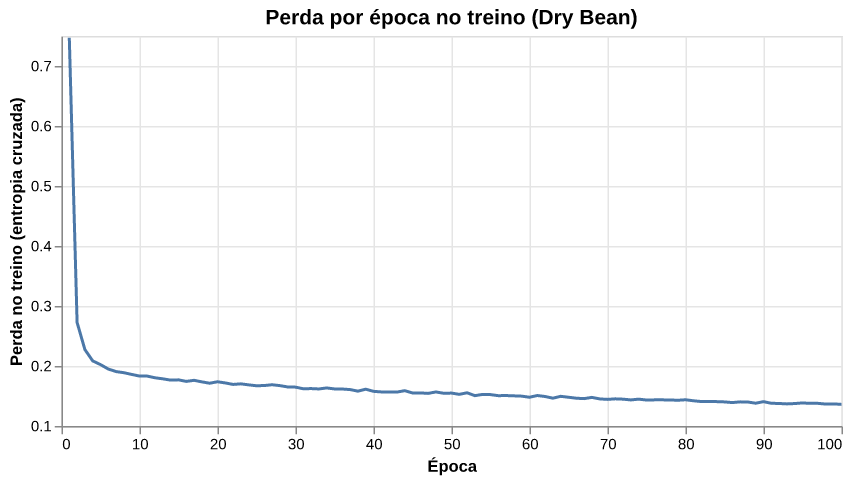

In [10]:
perda = pd.DataFrame({"epoca": np.arange(1, len(Rede.history["loss"]) + 1), "perda": Rede.history["loss"]})

stylize(alt.Chart(perda).mark_line().encode(
    x=alt.X("epoca:Q", title="Época"),
    y=alt.Y("perda:Q", title="Perda no treino (entropia cruzada)", scale=alt.Scale(zero=False)),
).properties(width=520, height=260, title="Perda por época no treino (Dry Bean)"))

A perda cai rápido nas primeiras 10 épocas e depois diminui devagar até o fim, sem instabilidade. Como a curva ainda desce um pouco na época 100, mais épocas reduziriam a perda no treino, mas a diferença entre treino e validação na tabela acima (95,1% contra 93,1%) indica que isso não deve melhorar muito o teste.

### Matriz de confusão

Cada linha é a classe real e cada coluna é a classe prevista pela rede.

In [11]:
classes = dict()
for indx, t in enumerate(np.unique(y_train)):
    classes[t] = indx

size_cl = len(classes)

In [12]:
matriz_confusao = np.zeros((size_cl, size_cl), dtype=int)

for pred, real in zip(y_previsto, y_test):
    matriz_confusao[classes[real], classes[pred]] += 1

print(matriz_confusao)

[[241   0  16   1   4   1   2]
 [  0 105   0   0   0   0   0]
 [  2   0 317   0   5   1   1]
 [  0   0   0 651   2   8  49]
 [  0   0   3   2 362   0   5]
 [  1   0   1   7   0 393   4]
 [  3   0   1  47  14   7 456]]


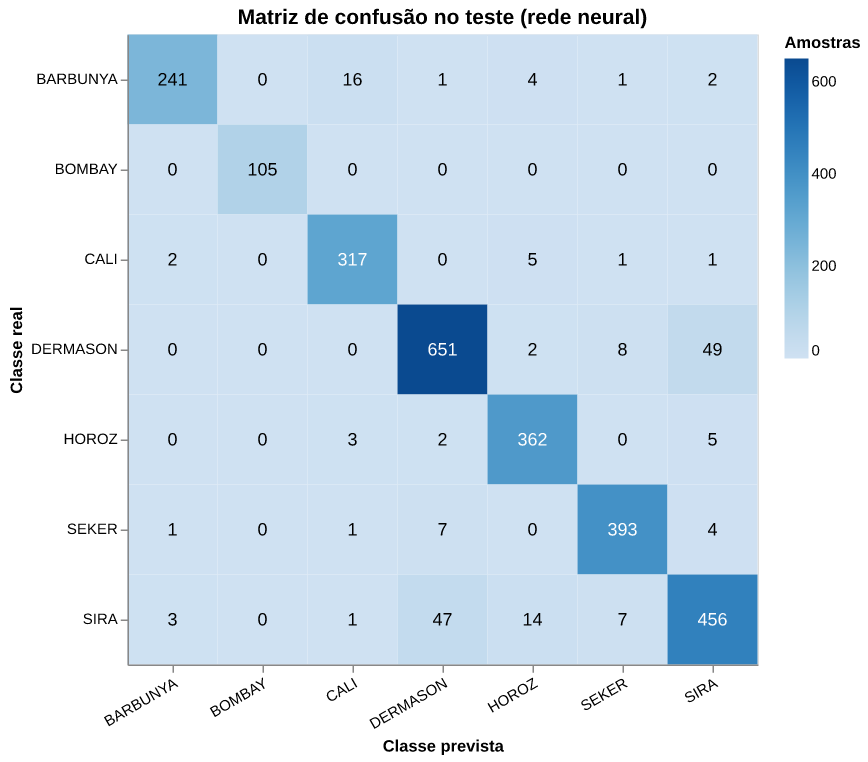

In [13]:
nomes = list(classes)
dados_matriz = pd.DataFrame(
    [{"real": nomes[i], "previsto": nomes[j], "contagem": int(matriz_confusao[i, j])}
     for i in range(size_cl) for j in range(size_cl)]
)

base = alt.Chart(dados_matriz).encode(
    x=alt.X("previsto:N", sort=nomes, title="Classe prevista", axis=alt.Axis(labelAngle=-30)),
    y=alt.Y("real:N", sort=nomes, title="Classe real"),
)
calor = base.mark_rect().encode(
    color=alt.Color("contagem:Q", scale=alt.Scale(scheme="blues"), title="Amostras")
)
numeros = base.mark_text(fontSize=12).encode(
    text="contagem:Q",
    color=alt.condition(alt.datum.contagem > 300, alt.value("white"), alt.value("black")),
)

stylize((calor + numeros).properties(width=420, height=420, title="Matriz de confusão no teste (rede neural)"))

### Métricas por classe

As métricas da `rbg` recebem primeiro o previsto e depois o real, e devolvem um valor por classe em ordem alfabética.

In [14]:
por_classe = pd.DataFrame({
    "classe": nomes,
    "amostras_reais": matriz_confusao.sum(axis=1),
    "amostras_previstas": matriz_confusao.sum(axis=0),
    "precision": Precision(y_previsto, y_test),
    "recall": Recall(y_previsto, y_test),
    "f1": F1Score(y_previsto, y_test),
})
por_classe.round(4)

,classe,amostras_reais,amostras_previstas,precision,recall,f1
0,BARBUNYA,265,247,0.9757,0.9094,0.9414
1,BOMBAY,105,105,1.0000,1.0000,1.0000
2,CALI,326,338,0.9379,0.9724,0.9548
3,DERMASON,710,708,0.9195,0.9169,0.9182
4,HOROZ,372,387,0.9354,0.9731,0.9539
5,SEKER,406,410,0.9585,0.9680,0.9632
6,SIRA,528,517,0.8820,0.8636,0.8727


In [15]:
nome_rede_clf = f"Rede neural (MLP {camadas_escolhidas})"
resultado_clf = metricas_classificacao(nome_rede_clf, y_previsto, y_test)
pd.DataFrame([resultado_clf]).round(4)

,modelo,acuracia,acuracia_balanceada,f1_macro
0,"Rede neural (MLP (128, 64))",0.931,0.9434,0.9435


In [16]:
# maiores confusões (fora da diagonal)
erros = dados_matriz[dados_matriz["real"] != dados_matriz["previsto"]]
erros.sort_values("contagem", ascending=False).head(6).reset_index(drop=True)

,real,previsto,contagem
0,DERMASON,SIRA,49
1,SIRA,DERMASON,47
2,BARBUNYA,CALI,16
3,SIRA,HOROZ,14
4,DERMASON,SEKER,8
5,SIRA,SEKER,7


A rede acertou 93,1% do teste (2525 de 2712). O erro mais comum é entre DERMASON e SIRA: 49 feijões DERMASON foram previstos como SIRA e 47 SIRA como DERMASON, o que sozinho dá cerca de metade dos 187 erros (96). Por isso a SIRA é a classe com as piores métricas (precision 0,882 e recall 0,864). Depois vêm BARBUNYA prevista como CALI (16 casos, o que derruba o recall da BARBUNYA para 0,909) e SIRA prevista como HOROZ (14). A BOMBAY foi acertada em todos os 105 casos.

In [17]:
salvar_resultados("redes_classificacao", [resultado_clf])

PosixPath('/home/fraga/Projects/Impatech/Machine_Learning/analise/agoravai/resultados/redes_classificacao.csv')

## Parte 2: regressão (Rent99)

Agora usamos o `MLPRegressor` para prever o aluguel. As variáveis e a divisão são as mesmas do notebook de regressão: `area`, `yearc`, `bath`, `kitchen`, `cheating` e as duas indicadoras de localização (`l2` e `l3`).

In [18]:
rent = carregar_rent99()
rent["l2"] = (rent["location"] == 2).astype(int)
rent["l3"] = (rent["location"] == 3).astype(int)

FEATURES_RENT = ['area', 'yearc', 'bath', 'kitchen', 'cheating', 'l2', 'l3']

X = rent[FEATURES_RENT]
y = rent['rent']

X_train, X_test, Y_train, Y_test = split_rent99(X, y)
print(X_train.shape, X_test.shape)

(2465, 7) (617, 7)


### Pré-processamento

Padronizamos X com o `Standard` ajustado no treino. Também padronizamos o alvo com a média e o desvio do treino, porque o aluguel está na casa das centenas de euros e, com os pesos iniciais pequenos, a rede demoraria muitas épocas só para chegar nessa escala. Na hora de prever, desfazemos a conta para voltar a euros.

In [19]:
def padronizar_alvo(y_ref):
    return y_ref.mean(), y_ref.std()


def treinar_regressor(camadas, X_tr, y_tr):
    # padroniza X e y com as estatísticas do treino e ajusta a rede
    padronizador = Standard()
    padronizador.fit(X_tr)
    media_y, desvio_y = padronizar_alvo(y_tr)
    rede = MLPRegressor(
        hidden_layers=camadas,
        activation='relu',
        optimizer="adam",
        learning_rate=0.001,
        epochs=100,
        batch_size=32,
        random_state=SEED,
    )
    rede.fit(padronizador.transform(X_tr), (y_tr - media_y) / desvio_y)
    return rede, padronizador, media_y, desvio_y


def prever_regressor(modelo, X_novo):
    rede, padronizador, media_y, desvio_y = modelo
    return rede.predict(padronizador.transform(X_novo)) * desvio_y + media_y

### Escolhendo a arquitetura

De novo separamos 20% do treino como validação e comparamos redes pequenas, já que temos poucas linhas e só 7 variáveis.

In [20]:
X_tr, X_val, Y_tr, Y_val = train_test_split(X_train, Y_train, test_size=0.2, random_state=SEED)

arquiteturas_reg = [(8,), (16,), (32, 16), (64, 32)]

comparacao_reg = []
for camadas in arquiteturas_reg:
    inicio = time.time()
    modelo = treinar_regressor(camadas, X_tr, Y_tr)
    comparacao_reg.append({
        "hidden_layers": str(camadas),
        "RMSE_treino": float(RMSE(prever_regressor(modelo, X_tr), Y_tr)),
        "RMSE_validacao": float(RMSE(prever_regressor(modelo, X_val), Y_val)),
        "tempo_s": round(time.time() - inicio, 1),
    })

comparacao_reg = pd.DataFrame(comparacao_reg)
comparacao_reg.round(2)

,hidden_layers,RMSE_treino,RMSE_validacao,tempo_s
0,"(8,)",134.96,134.84,0.5
1,"(16,)",131.17,131.09,0.4
2,"(32, 16)",128.23,129.83,0.7
3,"(64, 32)",126.27,135.93,0.8


In [21]:
melhor_reg = comparacao_reg.sort_values("RMSE_validacao").iloc[0]
camadas_reg = eval(melhor_reg["hidden_layers"])
print("Arquitetura escolhida pela validação:", camadas_reg)

Arquitetura escolhida pela validação: (32, 16)


A (32, 16) teve o menor RMSE de validação (129,8), contra 131,1 da (16,) e 134,8 da (8,). A maior, (64, 32), tem o menor erro no treino (126,3) mas piora na validação (135,9), sinal de sobreajuste. Ficamos com a (32, 16).

### Rede final e avaliação no teste

In [22]:
modelo_final = treinar_regressor(camadas_reg, X_train, Y_train)
Y_previsto = prever_regressor(modelo_final, X_test)

nome_rede_reg = f"Rede neural (MLP {camadas_reg})"
resultado_reg = metricas_regressao(nome_rede_reg, Y_previsto, Y_test)
pd.DataFrame([resultado_reg]).round(3)

,modelo,RMSE,MAE,R2
0,"Rede neural (MLP (32, 16))",147.739,105.993,0.516


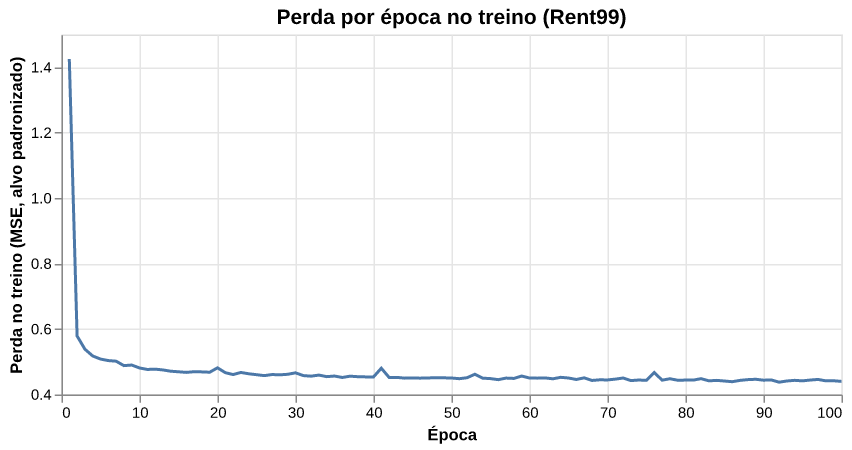

In [23]:
perda_reg = pd.DataFrame({"epoca": np.arange(1, 101), "perda": modelo_final[0].history["loss"]})

stylize(alt.Chart(perda_reg).mark_line().encode(
    x=alt.X("epoca:Q", title="Época"),
    y=alt.Y("perda:Q", title="Perda no treino (MSE, alvo padronizado)", scale=alt.Scale(zero=False)),
).properties(width=520, height=240, title="Perda por época no treino (Rent99)"))

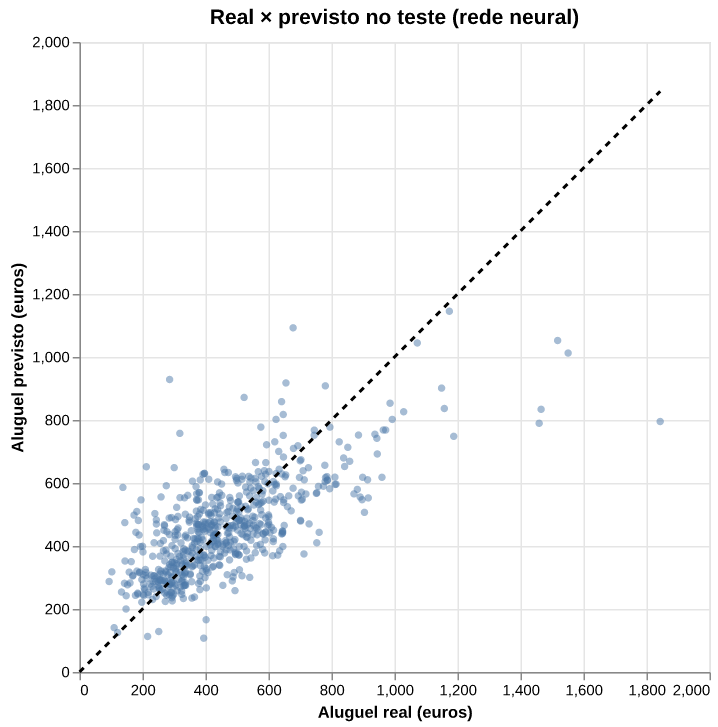

In [24]:
dados_prev = pd.DataFrame({"real": Y_test, "previsto": Y_previsto})
limites = [0, float(max(Y_test.max(), Y_previsto.max()))]

pontos = alt.Chart(dados_prev).mark_circle(size=25, opacity=0.5).encode(
    x=alt.X("real:Q", title="Aluguel real (euros)"),
    y=alt.Y("previsto:Q", title="Aluguel previsto (euros)"),
)
diagonal = alt.Chart(pd.DataFrame({"real": limites, "previsto": limites})).mark_line(
    color="black", strokeDash=[4, 4]
).encode(x="real:Q", y="previsto:Q")

stylize((pontos + diagonal).properties(width=420, height=420, title="Real × previsto no teste (rede neural)"))

No teste a rede teve RMSE de 147,7, MAE de 106,0 e R² de 0,516. Para referência, a regressão linear com essas mesmas variáveis e o mesmo split teve RMSE de aproximadamente 148,8 e R² de aproximadamente 0,509. A rede ficou cerca de 1 euro melhor no RMSE, o que na prática é um empate: com outra seed ou outra arquitetura a ordem poderia inverter. Isso sugere que, com poucas linhas (2465 no treino) e só 7 variáveis, a relação entre elas e o aluguel é quase linear e a rede não tem muito mais o que aprender. O gráfico mostra o mesmo problema do modelo linear: os aluguéis mais altos (acima de 1200 euros) são todos previstos abaixo do valor real.

In [25]:
salvar_resultados("redes_regressao", [resultado_reg])

PosixPath('/home/fraga/Projects/Impatech/Machine_Learning/analise/agoravai/resultados/redes_regressao.csv')

## Fechamento

Na classificação a rede chegou a 93,1% de acurácia e 0,943 de F1 macro no teste, com erros concentrados no par DERMASON e SIRA; a comparação com os outros classificadores fica para o relatório final, que junta os resultados de todos os notebooks. Na regressão a rede praticamente empatou com a regressão linear (RMSE 147,7 contra 148,8), que é mais simples, não precisa escolher arquitetura e tem coeficientes que dá para interpretar. Nos dois casos o treino levou poucos segundos, então o custo maior das redes aqui não é de tempo, e sim de ter mais hiperparâmetros para escolher e um modelo mais difícil de explicar.